# 03 - Before the fit: break energy and strahl verdict

Two quantities are measured **before** any component is fitted, because the staged fit
uses them to assign pixels to stages:

1. the **break energy** between core and suprathermal electrons (two-population
   crossing);
2. the **strahl side, strength and width**, from the pitch-angle distribution (PAD).

Both are cheap. The break energies are stored next to the data in
`<file stem>_two_population_crossing.csv`; the PAD verdict goes into the fit output.

**Runtime:** under a minute.

In [1]:
import os
import sys
from pathlib import Path

# Single-threaded linear algebra, set before numpy is imported: the fits are
# many small least-squares problems, and this makes the numbers in this
# notebook identical to those of the batch runner (which spawns 1-thread workers).
for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ.setdefault(name, '1')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Repository root = the first parent directory that contains src/evdf_poisson
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'evdf_poisson').is_dir())
sys.path.insert(0, str(REPO_ROOT / 'src'))

CALIBRATION_DIR = REPO_ROOT / 'examples' / 'example_data'          # EAS geometric factors, head geometry, scpot table
EXAMPLE_DIR = CALIBRATION_DIR / 'poisson_2023-04-04'                # the 30-epoch example subset
EXAMPLE_FILE = EXAMPLE_DIR / 'VDF_eas_forFitting_20230404005008_20230404011908_1min.h5'
RESULTS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_run_poisson'       # reference fit of the subset
DAYS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_days_2023-04-04_05'   # reference fit of the two full days
GEOMETRY_FILE = CALIBRATION_DIR / 'eas_head_geometry.npz'
print('repository:', REPO_ROOT)

repository: /disk/plasma/xw2/SO-EAS-eVDF_Fitting


## 1. Break energy: the two-population crossing

1. Take the **perpendicular cone** (pitch angles 90 $\pm$ 20 deg), where there is no
   strahl.
2. Average the PSD of *all* its pixels per energy step, zeros included. Averaging only
   the detected pixels would bias the faint channels upward.
3. Fit a Maxwellian core and a power-law tail **jointly** to that spectrum:

$$ f(E) = A_c\, e^{-E/kT_c} + A_t\, E^{-p} . $$

4. The break energy is where the two terms are equal, the standard core/halo
   definition (Stverak et al. 2009).

Fitting both terms at once avoids choosing a "core window" by hand. Only channels
resolved at 3 sigma or better enter, and the spectrum starts at
$12\,\text{eV} - \phi_{sc}$ (spacecraft secondaries below that). Epochs without a
crossing get a `status` other than `ok` and no break energy.

The functions are in `src/break_energy_methods.py`. Below they are called one by one on
a single epoch.

cone pixels: 17415   channels: 40   reliable: 34
status: ok   break = 139.0 eV   core T = 15.4 eV   tail index = 1.55


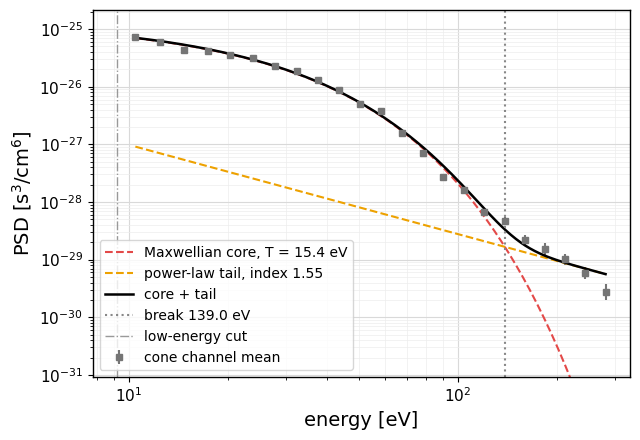

In [2]:
import break_energy_methods as bem
from data_io import load_data, convert_units
from evdf_poisson.plotting import plotBreakEnergyCrossing

EPOCH = 20
CONE_HALF_WIDTH_DEG = 20.0
data = convert_units(load_data(EXAMPLE_DIR, EXAMPLE_FILE.name))   # the whole file, CGS units
spacecraftPotential = float(data['scpot_aligned'][EPOCH])
lowCutEv = bem.BASELINE_LOW_ENERGY_EV - spacecraftPotential

profile, profileStatus = bem.buildConeProfile(EPOCH, data, CONE_HALF_WIDTH_DEG)
channels = bem.aggregateByEnergyChannel(profile)
crossing = bem.findTwoPopulationCrossing(channels, minEnergyEv=lowCutEv)

print(f'cone pixels: {len(profile)}   channels: {len(channels)}   reliable: {int(channels["is_reliable"].sum())}')
print(f"status: {crossing['status']}   break = {crossing['break_E_eV']:.1f} eV   "
      f"core T = {crossing['core_T_eV']:.1f} eV   tail index = {crossing['tail_index']:.2f}")
ax = plotBreakEnergyCrossing(crossing, lowCutEv=lowCutEv)

The channel table behind the figure. `detection_fraction` is the share of cone pixels
with at least one count. It drops below 10 % above ~300 eV, which is why the cone mean
includes the zeros.

In [3]:
shown = channels[channels['E_eV'] >= lowCutEv].iloc[::3]
shown[['E_eV', 'log_psd', 'n_pixels', 'total_count', 'detection_fraction', 'signal_to_noise', 'is_reliable']].round(3)

,E_eV,log_psd,n_pixels,total_count,detection_fraction,signal_to_noise,is_reliable
11,10.482,-25.146,405,579.0,0.758,22.085,True
14,17.374,-25.377,405,794.0,0.857,27.107,True
17,27.825,-25.635,405,1022.0,0.906,30.400,True
20,43.689,-26.059,405,884.0,0.872,25.679,True
23,67.799,-26.802,405,364.0,0.575,18.249,True
26,104.402,-27.794,405,87.0,0.190,8.672,True
29,159.990,-28.663,405,26.0,0.062,4.981,True
32,244.399,-29.236,405,16.0,0.040,3.992,True
35,372.579,-30.289,405,4.0,0.010,1.947,False
38,567.250,-31.374,405,1.0,0.002,1.000,False


### Whole files: `compute_break_energy_crossing.py`

The script (or `runCrossingPipeline`) does this for every epoch of every file in a
directory and writes `<file stem>_two_population_crossing.csv`. The fitting runner finds
it next to the data (or in `--break-dir`). Rerunning it here reproduces the file shipped
in `examples/example_data/`.

In [4]:
from compute_break_energy_crossing import runCrossingPipeline

runCrossingPipeline(EXAMPLE_DIR, EXAMPLE_DIR, workers=1, overwrite=True, writeCombined=False)
breakTable = pd.read_csv(EXAMPLE_DIR / (EXAMPLE_FILE.stem + '_two_population_crossing.csv'), parse_dates=['timestamp'])
breakTable[['epoch_id', 'timestamp', 'scpot_V', 'low_cut_eV', 'break_E_eV', 'core_T_eV', 'tail_index', 'status']].round(2)

1 files, 1 to process (0 already done), 1 workers


VDF_eas_forFitting_20230404005008_20230404011908_1min.h5: 30 epochs in 1 s, break ok 30/30


,epoch_id,timestamp,scpot_V,low_cut_eV,break_E_eV,core_T_eV,tail_index,status
0,0,2023-04-04 00:50:08,2.37,9.63,142.23,15.53,1.74,ok
1,1,2023-04-04 00:51:08,2.39,9.61,141.33,15.52,1.61,ok
2,2,2023-04-04 00:52:08,2.37,9.63,137.29,15.64,1.86,ok
3,3,2023-04-04 00:53:08,2.47,9.53,131.64,15.13,1.82,ok
4,4,2023-04-04 00:54:08,2.51,9.49,137.23,15.42,1.16,ok
5,5,2023-04-04 00:55:08,2.61,9.39,138.63,15.10,1.70,ok
6,6,2023-04-04 00:56:08,2.52,9.48,130.49,15.63,2.28,ok
7,7,2023-04-04 00:57:08,2.49,9.51,143.10,15.58,0.21,ok
8,8,2023-04-04 00:58:08,2.79,9.21,135.94,15.65,1.26,ok
9,9,2023-04-04 00:59:08,2.80,9.20,137.72,14.91,0.20,ok


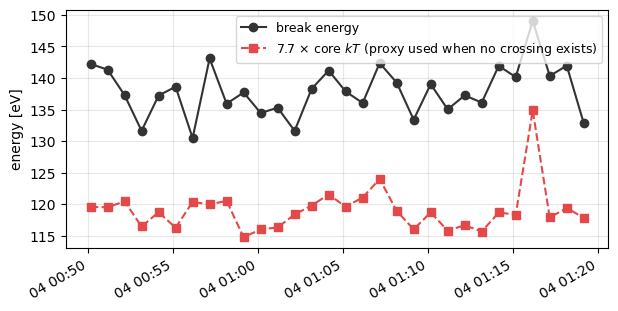

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(breakTable['timestamp'], breakTable['break_E_eV'], 'o-', color='0.2', label='break energy')
ax.plot(breakTable['timestamp'], 7.7 * breakTable['core_T_eV'], 's--', color='#e34948', label=r'7.7 $\times$ core $kT$ (proxy used when no crossing exists)')
ax.set_ylabel('energy [eV]'); ax.legend(fontsize=9); ax.grid(alpha=0.3); fig.autofmt_xdate()

## 2. Strahl detection from the PAD

The fit must know on which side of **B** the strahl is, how strong and how wide, and
must not invent one where there is none. All of that comes from the PAD:

1. **Band mean.** Average the PAD over $[\max(61, 0.8\,E_\text{break}),\ 1000]$ eV. The
   lower edge follows the break so the near-isotropic core does not dilute the beam
   contrast.
2. **Model.** Fit a background plus two Gaussians centred at 0 and 180 deg
   (Owen et al. 2022):
   $P(\alpha) = P_B + P_0\, e^{-\alpha^2 / 4W_0^2} + P_{180}\, e^{-(\alpha-180)^2 / 4W_{180}^2}$.
3. **Contrast and width.** For each side, the contrast against the perpendicular
   plateau, $\beta_\text{side} = \langle P\rangle_\text{side} / \langle P\rangle_{65-115^\circ} - 1$,
   and the beam width $\text{PAW} = 2\sqrt{2\ln 2}\, W$ (full width at half maximum).

The background $P_B$ is bounded below at 0.9 times the band mean. For a bright beam the
fitted plateau therefore sits above the perpendicular data, and $\beta$ is a
conservative contrast.

{'P_B': 65.66, 'P_0': -69.637, 'W_0': 10.0, 'P_180': 564.516, 'W_180': 10.0}


{'class': 'anti_strong',
 'sign': -1,
 'tier': 'strong',
 'beta_par': -0.42872672371818854,
 'beta_anti': 3.4753208527217323,
 'paw_par': 23.548200450309494,
 'paw_anti': 23.548200450309494,
 'deficit': ''}

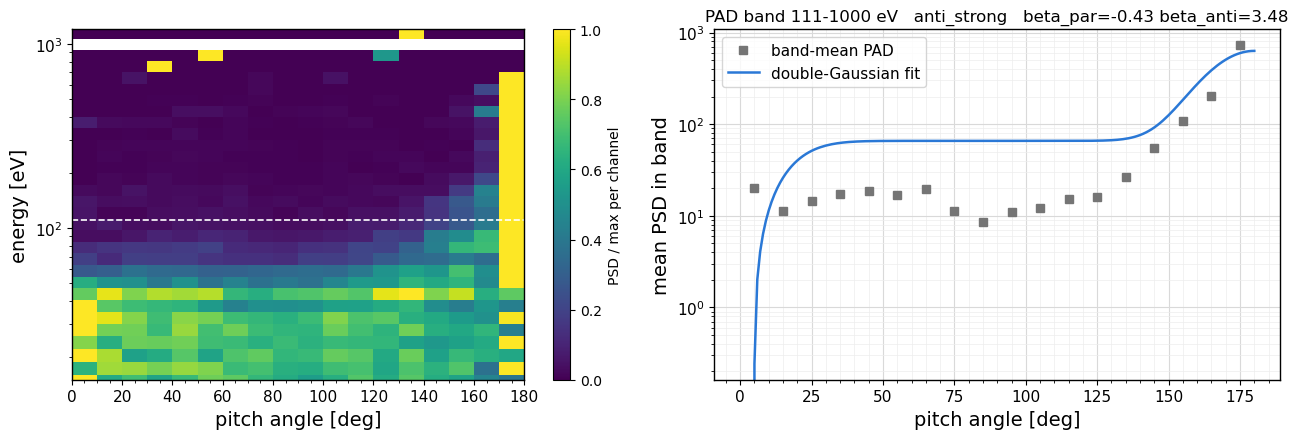

In [6]:
from evdf_poisson.pad_detection import fitBandMeanPad, detectStrahlFromPad
from evdf_poisson.plotting import plotPadSpectrogram, plotPadBandFit

breakEnergyEv = float(breakTable.loc[EPOCH, 'break_E_eV'])
padFit = fitBandMeanPad(EXAMPLE_FILE, EPOCH, breakEnergyEv)
detection = detectStrahlFromPad(EXAMPLE_FILE, EPOCH, breakEnergyEv)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plotPadSpectrogram(EXAMPLE_FILE, EPOCH, ax=axes[0], bandEv=padFit['band_ev'])
plotPadBandFit(padFit, detection, ax=axes[1])
fig.tight_layout()
print({name: round(param.value, 3) for name, param in padFit['params'].items()})
detection

### The two-tier verdict

| condition (per side) | tier | what the fit does |
|---|---|---|
| $\beta > 2$ and PAW $\le 60^\circ$ | **strong** | strahl component on that side, narrow perpendicular initial width |
| $0.6 < \beta \le 2$ and PAW $\le 60^\circ$ | **weak** | strahl component on that side, broad perpendicular initial width |
| otherwise | none | no strahl component (`quasi_iso`: 9 free parameters instead of 14) |
| $\beta < -0.5$ | *deficit* flag | recorded only; a sunward depletion, not fitted |

- If both sides qualify, the larger $\beta$ wins (`both`).
- $\beta > 2$ is the "meaningful strahl" threshold of Owen et al. (2022). The weak tier
  keeps scattered, broadened beams that the fit still has to account for.
- The 60 deg cap rejects fits that are not beams.

`seedFromData` receives the dictionary above: `sign` (+1 parallel, -1 anti-parallel,
0 none), `tier`, and the width `paw_par` / `paw_anti` that anchors the strahl's
perpendicular thermal speed.

In [7]:
verdicts = pd.DataFrame([{'epoch': epochIndex,
                          **detectStrahlFromPad(EXAMPLE_FILE, epochIndex, float(breakTable.loc[epochIndex, 'break_E_eV']))}
                         for epochIndex in range(len(breakTable))]).set_index('epoch')
verdicts.round(2)

,class,sign,tier,beta_par,beta_anti,paw_par,paw_anti,deficit
epoch,,,,,,,,
0,anti_strong,-1,strong,-0.93,5.01,105.97,17.16,par
1,anti_strong,-1,strong,-1.04,5.88,105.97,17.30,par
2,anti_strong,-1,strong,-0.42,3.27,23.55,23.55,
3,anti_strong,-1,strong,-0.93,5.46,105.97,19.20,par
4,anti_strong,-1,strong,-0.98,5.67,105.97,24.80,par
5,anti_strong,-1,strong,-0.45,3.36,23.55,23.55,
6,anti_strong,-1,strong,-0.92,5.28,105.97,21.09,par
7,anti_strong,-1,strong,-1.00,5.74,105.97,17.24,par
8,anti_strong,-1,strong,-1.06,5.92,105.97,21.66,par


## 3. What the fit does with the two numbers

- **Core stage:** pixels with $E \le E_\text{break}$, all pitch angles.
- **Halo stage:** pixels with $E > E_\text{break}$, outside both 30 deg cones.
- **Strahl stage:** the 30 deg cone on the detected side, all energies, only for a
  `strong` or `weak` verdict. The PAD width sets the initial perpendicular width.
- The strahl drift is searched in $[0.3, 3] \times v(E_\text{break})$.

Notebook 05 runs these stages one at a time.